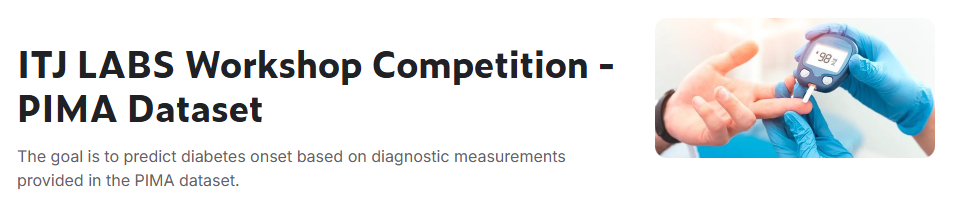
* kaggle : https://www.kaggle.com/competitions/itj-labs-workshop-competition-pima-dataset

```python
Pregnancies: Number of times the patient was pregnant.

Glucose: Plasma glucose concentration (mg/dL).

Blood Pressure: Diastolic blood pressure (mm Hg).

Skin Thickness: Triceps skinfold thickness (mm). Insulin: Serum insulin (μU/mL).

BMI: [CHECK] Body mass index (weight in kg/(height in m)^2).

Diabetes Pedigree Function: A function that scores the likelihood of diabetes based on family history.

Age: Age of the patient in years.

In [1]:
from sklearn import set_config
set_config(display="text")
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
sns.set()

import warnings
warnings.filterwarnings('ignore')

#-------------------- 차트 관련 속성 (한글처리, 그리드) -----------
plt.rcParams['font.family']= 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

from sklearn.model_selection import train_test_split  #---- 문제답 분리

from sklearn.linear_model import LogisticRegression             #---- 분류모델(선형모델)
from sklearn.ensemble import RandomForestClassifier             #---- 분류모델(트리모델)   
from sklearn.ensemble import VotingClassifier, VotingRegressor  #---- 분류모델(앙상블)  

from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, precision_recall_curve #---- 평가 메트릭스
from sklearn.metrics import roc_auc_score, roc_curve     #---- 평가 메트릭스
from sklearn.metrics import confusion_matrix, classification_report

from sklearn.model_selection import GridSearchCV, KFold, StratifiedKFold, cross_val_score, cross_validate  #----교차검증

from sklearn.preprocessing import LabelEncoder, OneHotEncoder                       #-----인코딩(글자->숫자변경)
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler        #-----정규화(스케일링)
from sklearn.decomposition import PCA                                               #-----차원축소


```python
sklearn.metrics.confusion_matrix(y_true, y_pred, *, labels=None, sample_weight=None, normalize=None)

sklearn.metrics.classification_report(y_true, y_pred, *, labels=None, target_names=None, sample_weight=None, digits=2, output_dict=False, zero_division='warn')

```python
class sklearn.model_selection.train_test_split(*arrays, test_size=None, train_size=None, random_state=None, shuffle=True, stratify=None)

class sklearn.model_selection.GridSearchCV(estimator, param_grid, *, scoring=None, n_jobs=None, refit=True, cv=None, verbose=0, pre_dispatch='2*n_jobs', error_score=nan, return_train_score=False)

class sklearn.model_selection.KFold(n_splits=5, *, shuffle=False, random_state=None)

class sklearn.model_selection.StratifiedKFold(n_splits=5, *, shuffle=False, random_state=None)

# **[1] Data Load**

In [2]:
train = pd.read_csv("../datas/pima/train.csv")   #, parse_dates=['datetime'])
test  = pd.read_csv("../datas/pima/test.csv") 

In [3]:
train.shape, test.shape

((616, 9), (152, 8))

In [4]:
train.head(2)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,2,90,60,0,0,23.5,0.191,25,0
1,2,92,52,0,0,30.1,0.141,22,0


* <b>컬럼 이름 소문자

In [5]:
train.columns = train.columns.str.lower()
test.columns  = test.columns.str.lower()

In [6]:
train = train.rename(columns={'bloodpressure':'bp',
                              'skinthickness' : 'skin',
                              'diabetespedigreefunction': 'diabet'})

test = test.rename(columns={'bloodpressure':'bp',
                            'skinthickness' : 'skin',
                            'diabetespedigreefunction': 'diabet'})

In [7]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 616 entries, 0 to 615
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   pregnancies  616 non-null    int64  
 1   glucose      616 non-null    int64  
 2   bp           616 non-null    int64  
 3   skin         616 non-null    int64  
 4   insulin      616 non-null    int64  
 5   bmi          616 non-null    float64
 6   diabet       616 non-null    float64
 7   age          616 non-null    int64  
 8   outcome      616 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 43.4 KB


# **[2] 1차점수 : 우선 점수만 보자**

## **공통함수**

In [8]:
def myscore(X_train7, y_train7, X_test3, y_test3, model=None) :
    if model is None : 
        #LogisticRegression, RandomForestClassifier
        model = RandomForestClassifier(
            n_estimators=100,
            random_state=1234
        )
    print(model.__class__.__name__)    
    model.fit(X_train7, y_train7)
    pred = model.predict(X_test3)
    
    acc = accuracy_score(y_test3, pred)
    print( f"acc : {acc:.4f}" )

In [9]:
def myscore222(df,  model=None, MY_TARGET="outcome") :
    X = df.drop(columns=['outcome'])
    y = df[MY_TARGET]
    X_train7, X_test3,    y_train7, y_test3 = train_test_split( X, y, test_size=0.3, shuffle=True, random_state=42)

    if model is None : 
        #LogisticRegression, RandomForestClassifier
        model = RandomForestClassifier(
            n_estimators=100,
            random_state=1234
        )
    print(model.__class__.__name__)    

    model.fit(X_train7, y_train7)
    pred = model.predict(X_test3)
    
    #--------------------------------------------------------------pred
    acc       = accuracy_score(y_test3, pred)
    f1        = f1_score(y_test3, pred)
    precision =  precision_score(y_test3, pred)
    recall    = recall_score(y_test3, pred)
    print(f"acc       : {acc:.4f}")
    print(f"f1        : {f1:.4f}")
    print(f"precision : {precision:.4f}")
    print(f"recall    : {recall:.4f}")
   
    cm = confusion_matrix(y_test3, pred)
    print(cm)

In [10]:
model = myscore222(train)

RandomForestClassifier
acc       : 0.7784
f1        : 0.6496
precision : 0.6441
recall    : 0.6552
[[106  21]
 [ 20  38]]


In [11]:
train.head(2)

,pregnancies,glucose,bp,skin,insulin,bmi,diabet,age,outcome
0,2,90,60,0,0,23.5,0.191,25,0
1,2,92,52,0,0,30.1,0.141,22,0


In [12]:
test.head(2)

,pregnancies,glucose,bp,skin,insulin,bmi,diabet,age
0,7,106,92,18,0,22.7,0.235,48
1,2,90,68,42,0,38.2,0.503,27


In [13]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 616 entries, 0 to 615
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   pregnancies  616 non-null    int64  
 1   glucose      616 non-null    int64  
 2   bp           616 non-null    int64  
 3   skin         616 non-null    int64  
 4   insulin      616 non-null    int64  
 5   bmi          616 non-null    float64
 6   diabet       616 non-null    float64
 7   age          616 non-null    int64  
 8   outcome      616 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 43.4 KB


In [14]:
test.info()

<class 'pandas.DataFrame'>
RangeIndex: 152 entries, 0 to 151
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   pregnancies  152 non-null    int64  
 1   glucose      152 non-null    int64  
 2   bp           152 non-null    int64  
 3   skin         152 non-null    int64  
 4   insulin      152 non-null    int64  
 5   bmi          152 non-null    float64
 6   diabet       152 non-null    float64
 7   age          152 non-null    int64  
dtypes: float64(2), int64(6)
memory usage: 9.6 KB


* <font color=red><b>결측있다 --> 보간
* <font color=red><b>글자있다 --> 인코딩

# **[3] 1차 EDA(Exploratory Data Analysis)**

## hist() : 데이터 분포도(왜도,첨도,정규분포)

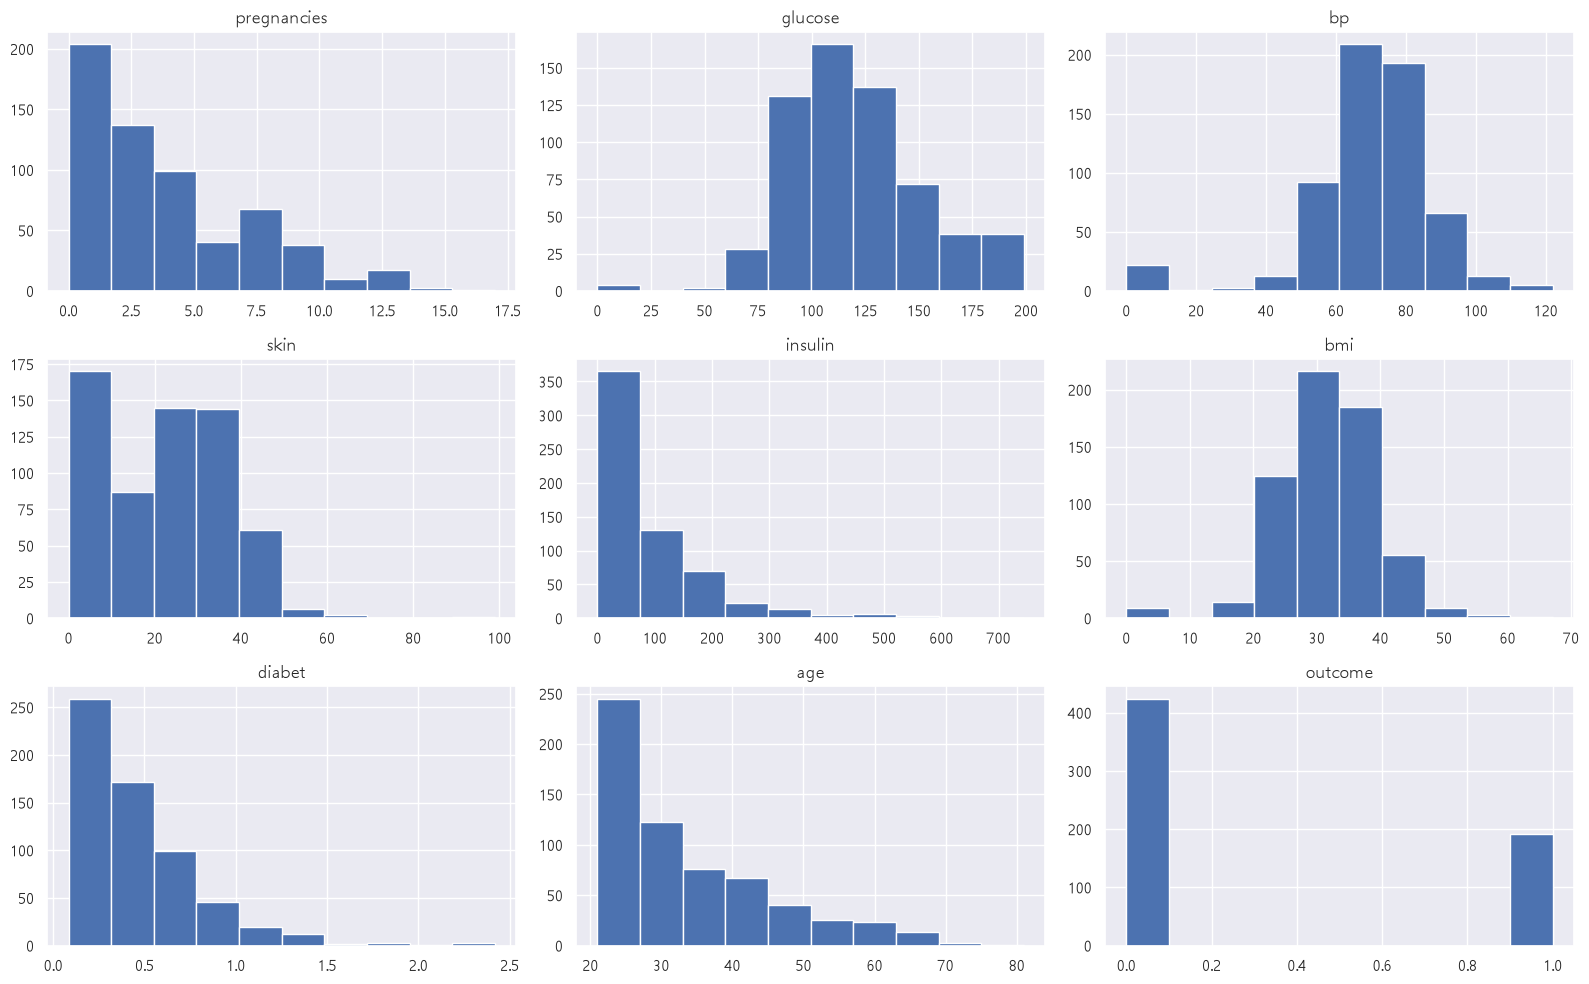

In [15]:
train.hist(figsize=(16,10))
plt.tight_layout()
plt.show()

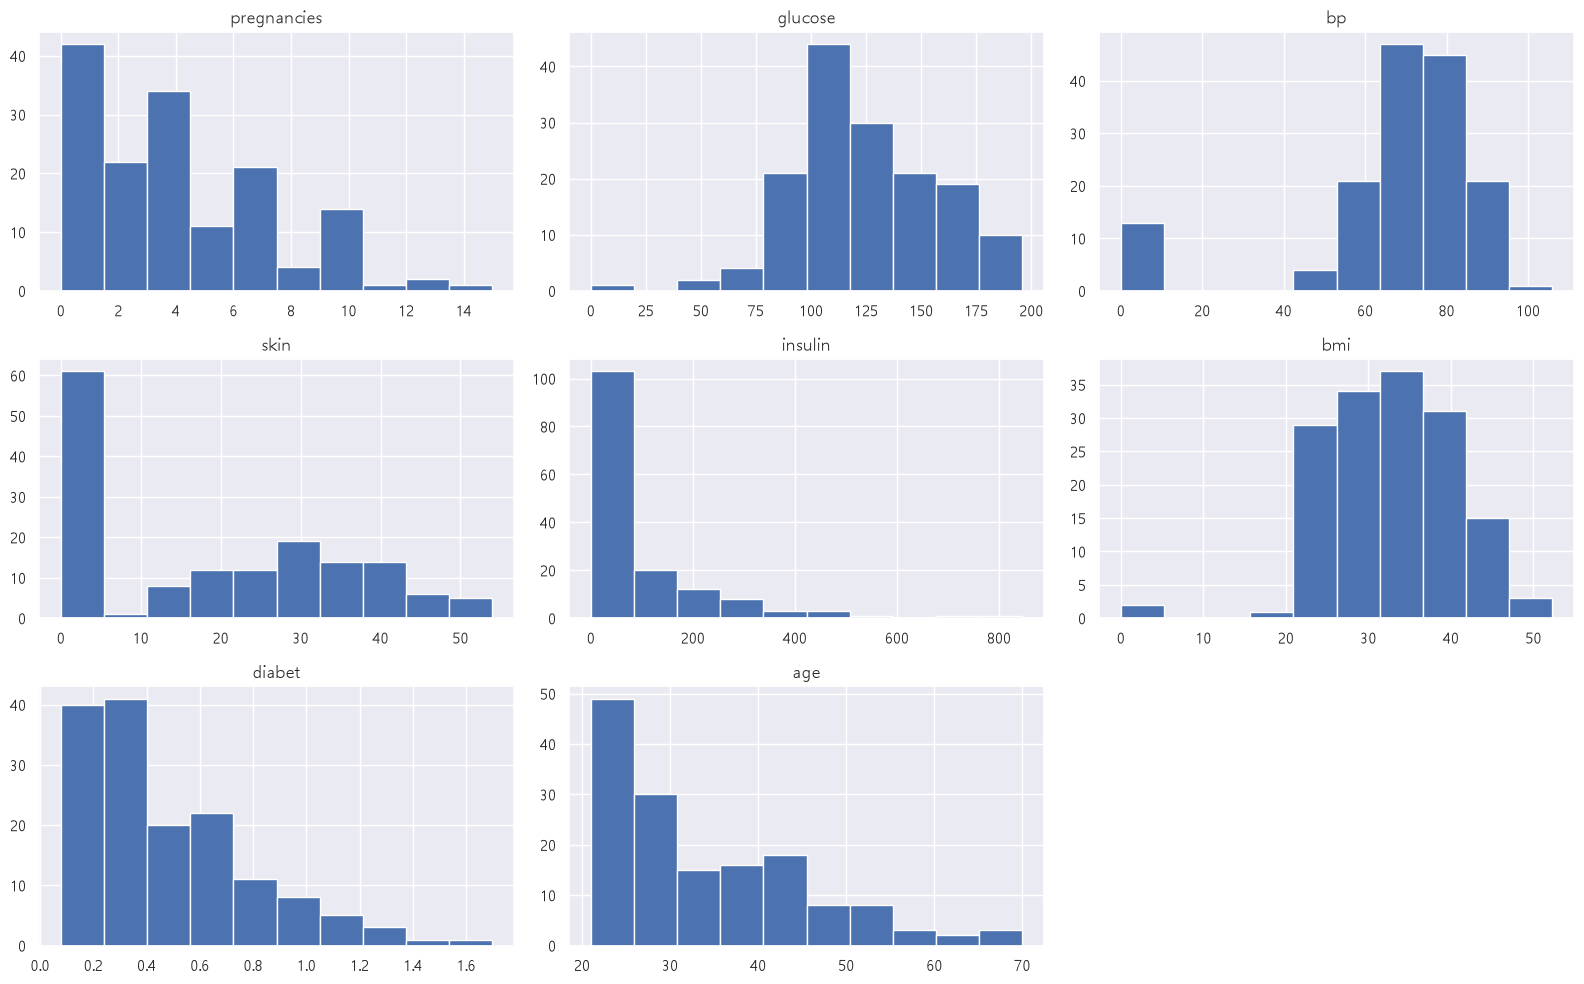

In [16]:
test.hist(figsize=(16,10))
plt.tight_layout()
plt.show()

## 이상치
* 0데이터

In [17]:
train[train['bp'] == 0]

,pregnancies,glucose,bp,skin,insulin,bmi,diabet,age,outcome
45,7,119,0,0,0,25.2,0.209,37,0
53,8,120,0,0,0,30.0,0.183,38,1
148,7,105,0,0,0,0.0,0.305,24,0
169,11,135,0,0,0,52.3,0.578,40,1
187,2,119,0,0,0,19.6,0.832,72,0
196,0,145,0,0,0,44.2,0.630,31,1
224,0,138,0,0,0,36.3,0.933,25,1
297,13,129,0,30,0,39.9,0.569,44,1
356,4,90,0,0,0,28.0,0.610,31,0
376,0,167,0,0,0,32.3,0.839,30,1


In [18]:
train.isin([0]).sum()

pregnancies     92
glucose          4
bp              22
skin           166
insulin        285
bmi              9
diabet           0
age              0
outcome        424
dtype: int64

In [19]:
#for col in train.columns :
    #cnt = train[train[col] == 0][col].count()
    #print(f"{col} : {cnt}") ----------------> for문 돌리는 법

# **[3] 전처리 & 가공**

* 결측처리
    * glucose
    * bp
    * skin
    * insulin
    * bmi

## 0 값을 NaN으로 변환 후 그룹별 평균으로 결측치 채우기

In [20]:
# 1. 결측치 대상 컬럼 지정
zero_features = ['glucose', 'bp', 'skin', 'insulin', 'bmi']

# 2. 0을 NaN으로 변환
train[zero_features] = train[zero_features].replace(0, np.nan)
test[zero_features] = test[zero_features].replace(0, np.nan)

# 3. Train 데이터의 유효 평균값으로 Train과 Test 모두 대치
for col in zero_features:
  mean_val = train[col].mean()  # NaN 제외 순수 평균
  train[col] = train[col].fillna(mean_val)
  test[col] = test[col].fillna(mean_val)

In [21]:
print(train[zero_features].isnull().sum())

glucose    0
bp         0
skin       0
insulin    0
bmi        0
dtype: int64


In [22]:
print(test[zero_features].isnull().sum())

glucose    0
bp         0
skin       0
insulin    0
bmi        0
dtype: int64


In [23]:
myscore222(train)

RandomForestClassifier
acc       : 0.7784
f1        : 0.6496
precision : 0.6441
recall    : 0.6552
[[106  21]
 [ 20  38]]


In [24]:
# Train 데이터 결측치 개수 확인
print('=== Train 데이터 결측치 수 ===')
print(train.isna().sum())

print('\n' + '=' * 30 + '\n')

# Test 데이터 결측치 개수 확인
print('=== Test 데이터 결측치 수 ===')
print(test.isna().sum())

=== Train 데이터 결측치 수 ===
pregnancies    0
glucose        0
bp             0
skin           0
insulin        0
bmi            0
diabet         0
age            0
outcome        0
dtype: int64


=== Test 데이터 결측치 수 ===
pregnancies    0
glucose        0
bp             0
skin           0
insulin        0
bmi            0
diabet         0
age            0
dtype: int64


In [25]:
# ==========================================
# [추가] 파생 피처 생성 (train과 test 양쪽에 모두 적용)
# ==========================================
# 1. 비만도(bmi)와 나이(age)를 조합한 파생 피처 생성
train['bmi_age_ratio'] = train['bmi'] / train['age']
test['bmi_age_ratio'] = test['bmi'] / test['age']

# 2. 포도당(glucose)과 인슐린(insulin) 비율 파생 피처 생성 (분모 0 방지 +1)
train['glucose_insulin_ratio'] = train['glucose'] / (train['insulin'] + 1)
test['glucose_insulin_ratio'] = test['glucose'] / (test['insulin'] + 1)

print('파생 피처 생성 완료! 현재 train 컬럼 개수:', train.shape[1])
print('현재 test 컬럼 개수:', test.shape[1])

파생 피처 생성 완료! 현재 train 컬럼 개수: 11
현재 test 컬럼 개수: 10


In [26]:
# 컬럼 목록 확인 (bmi_age_ratio, glucose_insulin_ratio가 들어왔는지 확인)
print(train.columns)

# 컬럼 개수 확인 (기존 9개에서 2개가 늘어나 11개가 되어야 정상입니다)
print(train.shape, test.shape)

Index(['pregnancies', 'glucose', 'bp', 'skin', 'insulin', 'bmi', 'diabet',
       'age', 'outcome', 'bmi_age_ratio', 'glucose_insulin_ratio'],
      dtype='str')
(616, 11) (152, 10)


## 3-1. 결측치 대치 직후 데이터 분포 및 상관관계 시각화

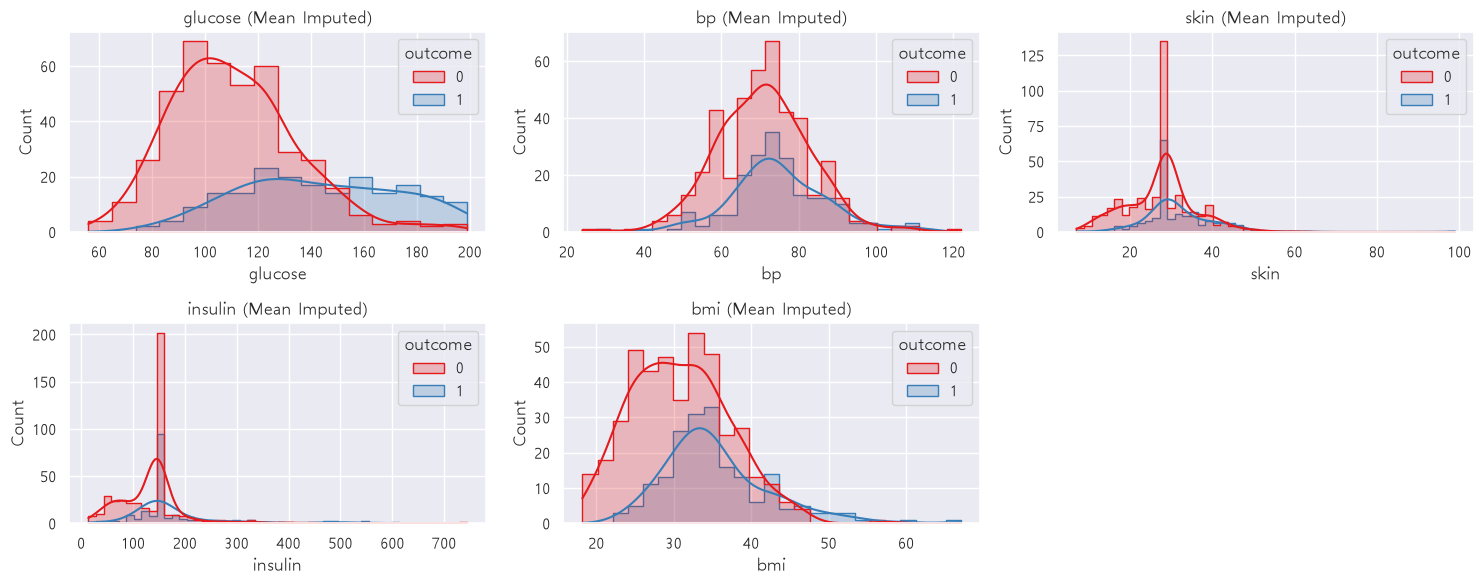

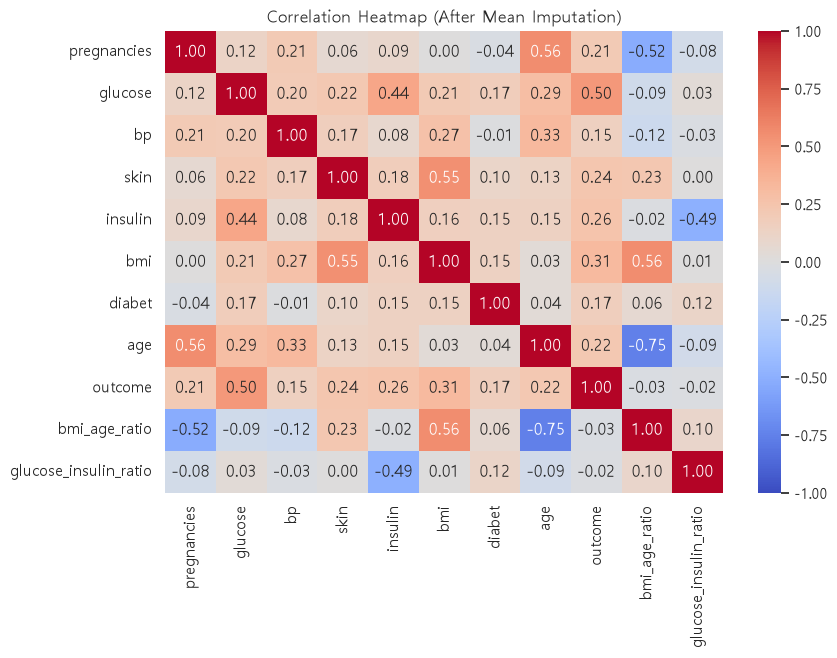

In [28]:
# 1. 시각화 대상 피처 (결측치 대치된 5개 피처 포함 원본 단위 상태)
zero_features = ['glucose', 'bp', 'skin', 'insulin', 'bmi']

# 2. 결측치 대치 직후 피처별 분포 (Outcome 구분)
plt.figure(figsize=(15, 6))
for i, col in enumerate(zero_features, 1):
  plt.subplot(2, 3, i)
  sns.histplot(
      data=train,
      x=col,
      hue='outcome',
      kde=True,
      element='step',
      palette='Set1',
  )
  plt.title(f'{col} (Mean Imputed)')

plt.tight_layout()
plt.show()

# 3. 결측치 대치 직후 상관계수 히트맵
plt.figure(figsize=(9, 6))
sns.heatmap(train.corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Heatmap (After Mean Imputation)')
plt.show()

ValueError: num must be an integer with 1 <= num <= 9, not 10

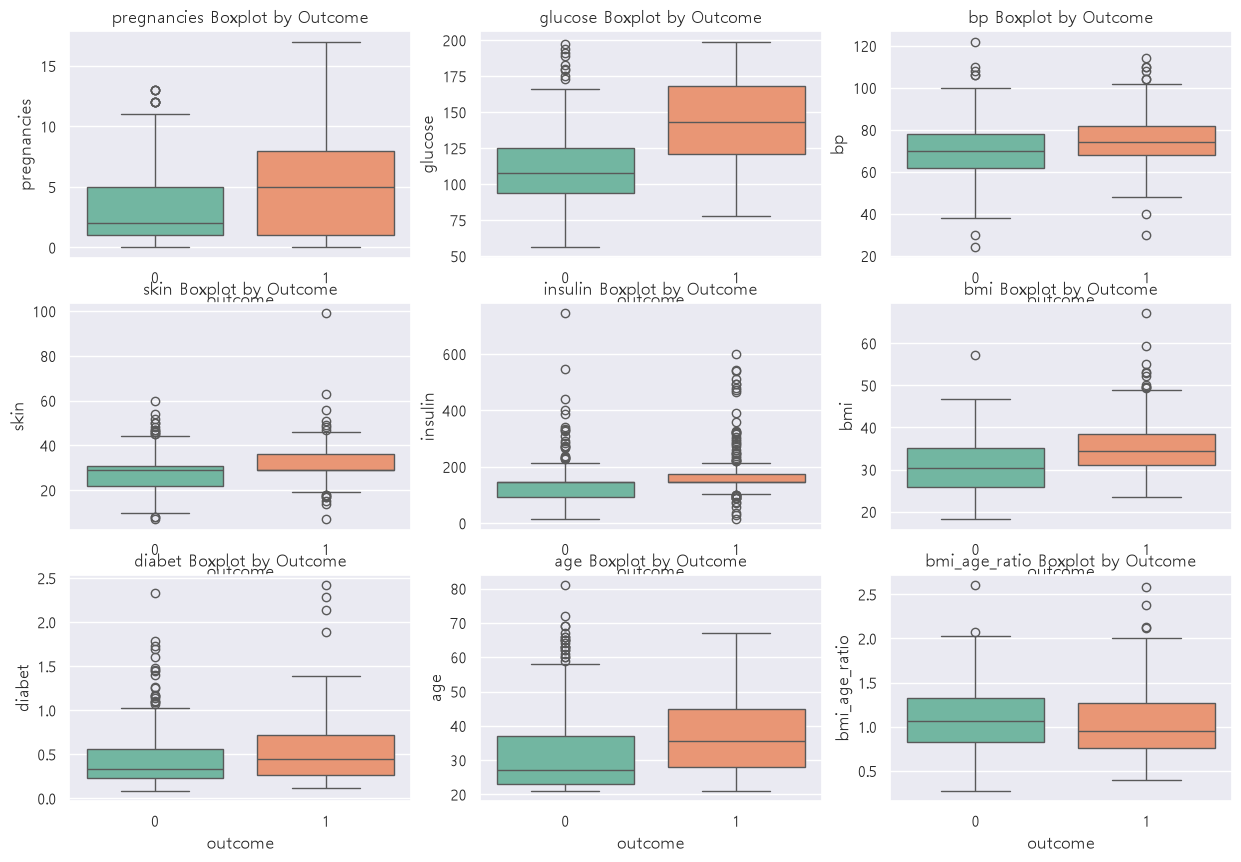

In [29]:
# outcome을 제외한 피처 목록
features = train.columns.drop('outcome')

# 3x3 격자로 피처별 박스플롯 생성
plt.figure(figsize=(15, 10))
for i, col in enumerate(features, 1):
  plt.subplot(3, 3, i)
  sns.boxplot(
      data=train, x='outcome', y=col, hue='outcome', palette='Set2', legend=False
  )
  plt.title(f'{col} Boxplot by Outcome')

plt.tight_layout()
plt.show()

In [31]:
# 1. outcome을 제외한 피처 들에 대해 RobustScaler 적용
features = train.columns.drop('outcome')

scaler = RobustScaler()

# 2. train은 학습 및 변환, test는 변환만 적용
train[features] = scaler.fit_transform(train[features])
test[features] = scaler.transform(test[features])

# 3. 스케일링 후 베이스라인 모델 성능 재측정
myscore222(train)

RandomForestClassifier
acc       : 0.7730
f1        : 0.6250
precision : 0.6481
recall    : 0.6034
[[108  19]
 [ 23  35]]


# **[5] 다양한 모델 비교 평가 (LogisticRegression, VotingClassifier)**

In [32]:
# 1. 비교 대상 모델 생성
lr = LogisticRegression(random_state=1234)
rf = RandomForestClassifier(random_state=1234)
vo = VotingClassifier(estimators=[('LR', lr), ('RF', rf)], voting='soft')

# 2. 각 모델별 성능 측정
models = [lr, rf, vo]

for model in models:
    print(f"=== {model.__class__.__name__} ===")
    myscore222(train, model)
    print("-" * 40)

=== LogisticRegression ===
LogisticRegression
acc       : 0.7946
f1        : 0.6481
precision : 0.7000
recall    : 0.6034
[[112  15]
 [ 23  35]]
----------------------------------------
=== RandomForestClassifier ===
RandomForestClassifier
acc       : 0.7730
f1        : 0.6250
precision : 0.6481
recall    : 0.6034
[[108  19]
 [ 23  35]]
----------------------------------------
=== VotingClassifier ===
VotingClassifier
acc       : 0.8000
f1        : 0.6606
precision : 0.7059
recall    : 0.6207
[[112  15]
 [ 22  36]]
----------------------------------------


In [33]:
# 1. LightGBM 라이브러리 임포트
from lightgbm import LGBMClassifier

# 2. 공통 함수에 LightGBM 대입해서 실행
myscore222(train, model=LGBMClassifier(class_weight='balanced', random_state=42, verbose=-1))

LGBMClassifier
acc       : 0.7351
f1        : 0.6142
precision : 0.5652
recall    : 0.6724
[[97 30]
 [19 39]]


In [34]:
myscore222(train)

RandomForestClassifier
acc       : 0.7730
f1        : 0.6250
precision : 0.6481
recall    : 0.6034
[[108  19]
 [ 23  35]]


In [35]:
# 1. 독립변수(X)와 종속변수(y) 분리
X = train.drop(columns=['outcome'])
y = train['outcome']

# 2. Train / Validation 데이터 세트 분할 (8:2 비율)
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

In [36]:
# 1. outcome을 제외한 피처 들에 대해 RobustScaler 적용
features = train.columns.drop('outcome')

scaler = RobustScaler()
train_scaled = train.copy()
train_scaled[features] = scaler.fit_transform(train[features])

# 2. 스케일링 적용 후 동일 공통함수로 점수 비교
myscore222(train_scaled)

RandomForestClassifier
acc       : 0.7730
f1        : 0.6250
precision : 0.6481
recall    : 0.6034
[[108  19]
 [ 23  35]]


In [37]:
# 원본 데이터 훼손 방지를 위해 안전하게 복사본 생성
train_scaled_copy = train_scaled.copy()

# 비교할 후보 모델 리스트 정의
models = [
    LogisticRegression(random_state=1234),
    VotingClassifier(
        estimators=[
            ('rf', RandomForestClassifier(random_state=1234)),
            ('lr', LogisticRegression(random_state=1234)),
        ],
        voting='soft',
    ),
]

# 복사본 데이터로 모델별 성능 평가 진행
for m in models:
  myscore222(train_scaled_copy, model=m)
  print('-' * 40)

LogisticRegression
acc       : 0.7946
f1        : 0.6481
precision : 0.7000
recall    : 0.6034
[[112  15]
 [ 23  35]]
----------------------------------------
VotingClassifier
acc       : 0.8000
f1        : 0.6606
precision : 0.7059
recall    : 0.6207
[[112  15]
 [ 22  36]]
----------------------------------------


In [38]:
# # 1. 랜덤 포레스트 모델 준비
# rf_model = RandomForestClassifier(random_state=42)rf_model = RandomForestClassifier(random_state=42)

# # 2. train 데이터로 학습 (outcome 컬럼 제외)
# X_train_all = train.drop(columns=['outcome'])
# y_train_all = train['outcome']
# rf_model.fit(X_train_all, y_train_all)

# # 3. test 데이터 예측 (outcome 컬럼이 있다면 제외)
# X_test = test.drop(columns=['outcome'], errors='ignore')
# rf_pred = rf_model.predict(X_test)

# # 4. 제출 파일 생성 및 저장
# submission_rf = pd.DataFrame({'ID': test.index, 'Outcome': rf_pred})
# submission_rf.to_csv('rf_submission.csv', index=False)

# print('rf_submission.csv 파일 생성 완료!')
# # 2. train 데이터로 학습 (outcome 컬럼 제외)
# X_train_all = train.drop(columns=['outcome'])
# y_train_all = train['outcome']
# rf_model.fit(X_train_all, y_train_all)

# # 3. test 데이터 예측 (outcome 컬럼이 있다면 제외)
# X_test = test.drop(columns=['outcome'], errors='ignore')
# rf_pred = rf_model.predict(X_test)

# # 4. 제출 파일 생성 및 저장
# submission_rf = pd.DataFrame({'ID': test.index, 'Outcome': rf_pred})
# submission_rf.to_csv('rf_submission.csv', index=False)

# print('rf_submission.csv 파일 생성 완료!'

# [6] CV

In [39]:
# 1. 모델과 StratifiedKFold 설정 (데이터 비율을 고르게 섞어가며 5등분)
rf_cv_model = RandomForestClassifier(random_state=42)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 2. X와 y 데이터 분리
X = train.drop(columns=['outcome'])
y = train['outcome']

# 3. 교차 검증 수행 (평가지표는 정확도 기준)
cv_scores = cross_val_score(rf_cv_model, X, y, cv=skf, scoring='accuracy')

# 4. 결과 확인
print(f"각 폴드별 정확도: {cv_scores}")
print(f"교차 검증 평균 정확도: {cv_scores.mean():.4f}")
print(f"표준편차: {cv_scores.std():.4f}")

각 폴드별 정확도: [0.79032258 0.73170732 0.7804878  0.79674797 0.79674797]
교차 검증 평균 정확도: 0.7792
표준편차: 0.0245


# [7] CM

In [40]:
# # 새로운 임포트 없이, 이미 네가 다 불러놓은 것들만 그대로 사용
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# # 모델 학습 및 예측
# rf_cv_model.fit(X_train, y_train)
# y_pred = rf_cv_model.predict(X_test)

# # 이미 네가 임포트해 둔 함수로 혼동 행렬 출력
# cm = confusion_matrix(y_test, y_pred)
# print("혼동 행렬 (Confusion Matrix):")
# print(cm)

# print("\n[상세 분류 보고서]")
# print(classification_report(y_test, y_pred))

In [41]:
# # 1. class_weight를 추가한 랜덤 포레스트 정의
# rf_balanced = RandomForestClassifier(class_weight='balanced', random_state=42)

# # 2. 학습 및 예측
# rf_balanced.fit(X_train, y_train)
# y_pred_balanced = rf_balanced.predict(X_test)

# # 3. 결과 확인
# print("--- [Class Weight 적용 후 혼동 행렬] ---")
# print(confusion_matrix(y_test, y_pred_balanced))
# print("\n[상세 분류 보고서]")
# print(classification_report(y_test, y_pred_balanced))

# [8] 파라미터 조절

In [42]:
# 1. 트리 개수를 늘리고 깊이를 제한해서 일반화 성능 높이기
model_1 = RandomForestClassifier(
    n_estimators=300, 
    max_depth=10, 
    class_weight='balanced', 
    random_state=42
)

# 2. 리프 노드 최소 샘플 수를 조정해서 과적합(Overfitting) 막기
model_2 = RandomForestClassifier(
    n_estimators=200, 
    max_depth=8, 
    min_samples_split=5, 
    class_weight='balanced', 
    random_state=42
)

# 공통 함수에 대입해서 실행해보기
myscore222(train, model=model_1)

RandomForestClassifier
acc       : 0.7405
f1        : 0.6471
precision : 0.5641
recall    : 0.7586
[[93 34]
 [14 44]]


In [43]:
# 가중치를 'balanced' 대신 조금 더 부드럽게 조정하고, 깊이도 낮춰서 과민반응 잡기
model_tuned = RandomForestClassifier(
    n_estimators=200,
    max_depth=5,
    class_weight={0: 1, 1: 1.5},  # 환자 가중치를 조금만 더 줌
    random_state=42
)

myscore222(train, model=model_tuned)

RandomForestClassifier
acc       : 0.7730
f1        : 0.6719
precision : 0.6143
recall    : 0.7414
[[100  27]
 [ 15  43]]


In [44]:
model_final_push = RandomForestClassifier(
    n_estimators=300,
    max_depth=6,
    class_weight={0: 1, 1: 1.7},  # 1.5와 balanced 사이의 황금 비율 타격
    min_samples_split=4,
    random_state=42
)

myscore222(train, model=model_final_push)

RandomForestClassifier
acc       : 0.7514
f1        : 0.6515
precision : 0.5811
recall    : 0.7414
[[96 31]
 [15 43]]


In [48]:
test.head(2)

,pregnancies,glucose,bp,skin,insulin,bmi,diabet,age,bmi_age_ratio,glucose_insulin_ratio
0,0.8,-0.275,1.25,-1.549524,0.0,-1.137725,-0.379049,1.1875,-1.094396,-0.298851
1,-0.2,-0.675,-0.25,1.879048,0.0,0.718563,0.359752,-0.1250,0.733206,-0.544061


In [49]:
train.head(2)

,pregnancies,glucose,bp,skin,insulin,bmi,diabet,age,outcome,bmi_age_ratio,glucose_insulin_ratio
0,-0.2,-0.675,-0.75,0.0,0.0,-1.041916,-0.500345,-0.2500,0,-0.188096,-0.544061
1,-0.2,-0.625,-1.25,0.0,0.0,-0.251497,-0.638181,-0.4375,0,0.642723,-0.513410


In [45]:
# 1. 최적의 파라미터로 최종 랜덤 포레스트 모델 준비
final_rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=6,
    class_weight={0: 1, 1: 1.7},
    min_samples_split=4,
    random_state=42
)

# 2. train 전체 데이터로 학습
X_train_all = train.drop(columns=['outcome'])
y_train_all = train['outcome']
final_rf_model.fit(X_train_all, y_train_all)

# 3. test 데이터 예측 (안전 장치 포함)
X_test = test.drop(columns=['outcome'], errors='ignore')
rf_pred = final_rf_model.predict(X_test)

# 4. 제출 파일 생성 및 저장
submission_rf = pd.DataFrame({'ID': test.index, 'Outcome': rf_pred})
submission_rf.to_csv('tuned_rf_submission.csv', index=False)

print('tuned_rf_submission.csv 파일 생성 완료!')

tuned_rf_submission.csv 파일 생성 완료!


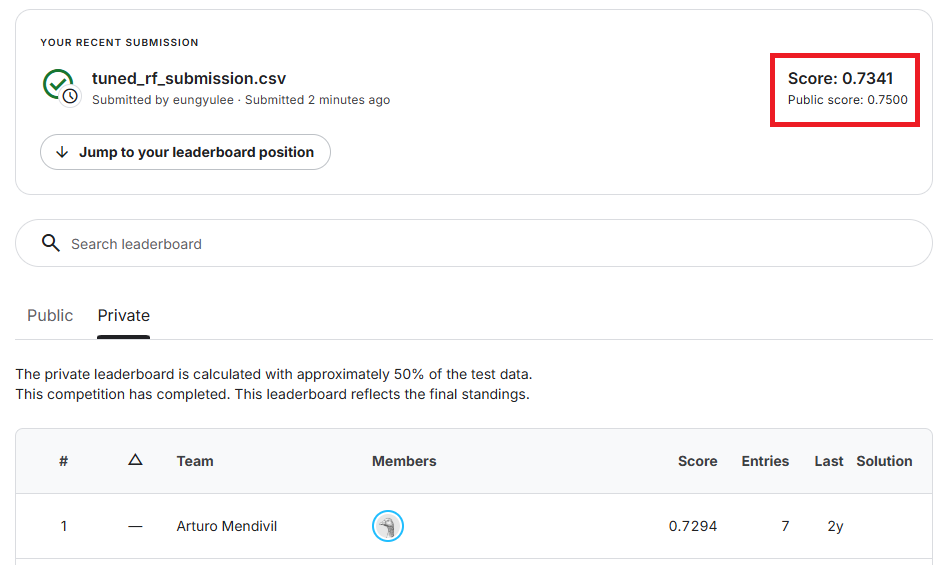